In [30]:
import torch
import torch.nn as nn

import torchvision
from torchvision.transforms import v2
import numpy as np
from torch.utils.data import DataLoader, Dataset, random_split

In [ ]:
dataset_caltech101 = torchvision.datasets.Caltech101(root='', download=False)
labels = np.array(dataset_caltech101.y)

In [ ]:
# accessing data from folder saved in local device
# dataset_caltech101 = torchvision.datasets.ImageFolder(root=r'caltech101\data_classes')
# labels = np.array(dataset_caltech101.targets)

In [33]:

# naive split
"""train = int(0.8 * len(dataset_caltech101))
test = len(dataset_caltech101) - train

train_set, test_set = random_split(
    dataset_caltech101, [train, test]
)

print(len(train_set))
print(len(test_set))"""

'train = int(0.8 * len(dataset_caltech101))\ntest = len(dataset_caltech101) - train\n\ntrain_set, test_set = random_split(\n    dataset_caltech101, [train, test]\n)\n\nprint(len(train_set))\nprint(len(test_set))'

In [34]:
len(dataset_caltech101)

8677

In [35]:
# Stratified split: take TRAIN_FRAC of each class (at least 1 sample in each split).
rng = np.random.default_rng(42)
train_idx, test_idx = [], []


for c in range(101):
    idx = np.where(labels == c)[0]
    rng.shuffle(idx)
    n_train = min(max(1, int(round(0.8 * len(idx)))), len(idx) - 1)
    train_idx.extend(idx[:n_train].tolist())
    test_idx.extend(idx[n_train:].tolist())

print('train:', len(train_idx), '| test:', len(test_idx))
assert set(train_idx).isdisjoint(test_idx)
assert len(train_idx) + len(test_idx) == len(dataset_caltech101)

train: 6941 | test: 1736


In [36]:
class TransformedSubset(Dataset):
    """A subset of `Base_dataset` that applies its own transform (so train and test can differ)."""
    def __init__(self, Base_dataset, indices, transform):
        self.Base_dataset, self.indices, self.transform = Base_dataset, indices, transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        img, label = self.Base_dataset[self.indices[i]]
        return self.transform(img), label

In [37]:
IMG_SIZE = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]    # pretrained imagenet weights
base_data = dataset_caltech101

In [38]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu'
print(device)

cuda


In [39]:
train_tfm = v2.Compose([
    v2.RGB(),                                            # handles grayscale and RGBA
    v2.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0), antialias=True),
    v2.RandomHorizontalFlip(),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])

test_tfm = v2.Compose([                                   # deterministic
    v2.RGB(),
    v2.Resize(256, antialias=True),
    v2.CenterCrop(IMG_SIZE),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])

train_dataset = TransformedSubset(base_data, train_idx, train_tfm)
test_dataset = TransformedSubset(base_data, test_idx, test_tfm)

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True,
                          drop_last=True)   # avoids a size-1 final batch for BatchNorm
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False)

In [40]:
import matplotlib.pyplot as plt
import numpy as np

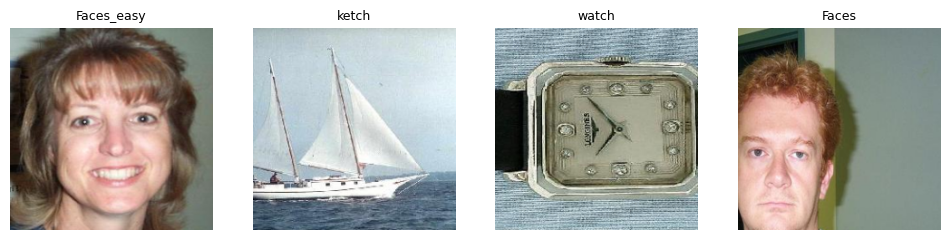

In [41]:
# Visualize a few training samples with class names
mean_t = torch.tensor(MEAN).view(-1, 1, 1)
std_t = torch.tensor(STD).view(-1, 1, 1)

def unnormalize(t):
    return torch.clamp(t * std_t + mean_t, 0, 1)

images, ys = next(iter(train_loader))
fig, axes = plt.subplots(1, 4, figsize=(12, 3.5))
for ax, img, y in zip(axes, images[:4], ys[:4]):
    ax.imshow(unnormalize(img).permute(1, 2, 0).numpy())
    ax.set_title(base_data.categories[y.item()], fontsize=9)
    ax.axis('off')
plt.show()

### Training Functions

In [42]:
def train_one_epoch(epoch_index, model, optimizer, criterion):
    running_loss = 0.

    # Here, we use enumerate(training_loader) instead of
    # iter(training_loader) so that we can track the batch
    # index and do some intra-epoch reporting
    for inputs, labels in (train_loader):
        # Every data instance is an input + label pair
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero your gradients for every batch!
        optimizer.zero_grad()

        # Make predictions for this batch
        outputs = model(inputs)

        # Compute the loss and its gradients
        loss = criterion(outputs, labels)
        loss.backward()

        # Adjust learning weights
        optimizer.step()

        # Gather data and report
        running_loss += loss.item()

    return running_loss/len(train_loader)

In [43]:
def eval_one_epoch(index, model, criterion):

    running_vloss = 0.0

    # Disable gradient computation and reduce memory consumption.
    with torch.no_grad():
        for vinputs, vlabels in (test_loader):
            vinputs, vlabels = vinputs.to(device), vlabels.to(device)
            voutputs = model(vinputs)
            vloss = criterion(voutputs, vlabels)
            running_vloss += vloss.item()

    return running_vloss / (len(test_loader))

In [44]:
model = torchvision.models.resnet18(weights='IMAGENET1K_V1')
print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 156MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [45]:
# ConvNet as fixed feature extractor --> freeze weights
for param in model.parameters():
  param.requires_grad = False

# Parameters of newly constructed modules have requires_grad=True by default
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 101)

In [46]:
print(model.fc)

Linear(in_features=512, out_features=101, bias=True)


In [47]:
model = model.to(device)

In [48]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)

In [49]:
EPOCHS = 20
epoch_number = 0

for epoch in range(EPOCHS):
    print(f'EPOCH {epoch_number + 1}:')

    # Make sure gradient tracking is on, and do a pass over the data
    model.train(True)
    avg_loss = train_one_epoch(epoch_number, model, optimizer, criterion)


    # Set the model to evaluation mode, disabling dropout and using population
    # statistics for batch normalization.
    model.eval()
    avg_vloss = eval_one_epoch(epoch_number, model, criterion)

    epoch_number +=1
    print(f'LOSS train {avg_loss} valid {avg_vloss}')

EPOCH 1:
LOSS train 1.9982058947793173 valid 0.5740903258789055
EPOCH 2:
LOSS train 0.8926598423292125 valid 0.4282216975700128
EPOCH 3:
LOSS train 0.7311211466198781 valid 0.4518843920672598
EPOCH 4:
LOSS train 0.6280250330495525 valid 0.46427928074369723
EPOCH 5:
LOSS train 0.5882069045864314 valid 0.5298671117026458
EPOCH 6:
LOSS train 0.540568771932426 valid 0.46829072712935116
EPOCH 7:
LOSS train 0.5175482569913489 valid 0.4295527685514078
EPOCH 8:
LOSS train 0.5284549669067624 valid 0.4160389995605117
EPOCH 9:
LOSS train 0.506536521921087 valid 0.4681175833350986
EPOCH 10:
LOSS train 0.51125854993424 valid 0.48572187465691846
EPOCH 11:
LOSS train 0.47048712141395166 valid 0.4190547692117774
EPOCH 12:
LOSS train 0.430251884159667 valid 0.5298074800842917
EPOCH 13:
LOSS train 0.44140645942968465 valid 0.4806896532942387
EPOCH 14:
LOSS train 0.4402940641047372 valid 0.4887994438312401
EPOCH 15:
LOSS train 0.4856946211245588 valid 0.47679275079030053
EPOCH 16:
LOSS train 0.4660237334

In [50]:
def evaluate_multiclass_accuracy(model, test_loader):
    # Set model to evaluation mode (turns off dropout and fixes batchnorm layers)
    model.eval()

    total_correct = 0
    total_samples = 0

    # Disable gradient tracking to save memory and speed up computation
    with torch.no_grad():
        for inputs, targets in test_loader:
            # Move data to the active device (CPU or GPU)
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass to get raw logits: shape (batch_size, num_classes)
            logits = model(inputs)

            # 1. Get the predicted class indices along the class dimension (dim=1)
            preds = torch.argmax(logits, dim=1)

            # 2. Compare predictions to ground truth labels and sum the correct matches
            correct_batch = (preds == targets).sum().item()

            # 3. Accumulate total correct predictions and total samples seen
            total_correct += correct_batch
            total_samples += targets.size(0)

    # Calculate final accuracy across the entire test dataset
    final_accuracy = total_correct / total_samples
    return final_accuracy

# --- Example Usage ---

test_acc = evaluate_multiclass_accuracy(model, test_loader)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Test Accuracy: 90.26%
